# 9. Sums: Euler–Maclaurin and the Stirling series

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 4 and 5

Physics often needs sums that cannot be done in closed form: partition functions
over quantum levels, lattice sums, sums over modes. When the terms vary slowly from
one to the next, the sum is close to an integral, and the **Euler–Maclaurin formula**
gives the corrections as a series in the derivatives of the summand at the ends of
the range. The series is asymptotic: it usually diverges, and the methods of
Chapters 1 and 4 apply. This chapter derives the formula, uses it to compute slowly
convergent sums to full precision, obtains the Stirling series for the factorial as a
by-product, and applies it to the rotational partition function of a diatomic
molecule.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
import sympy as sp

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 40

## 9.1 The Euler–Maclaurin formula

For a smooth function $f$ and integers $a < b$,

$$ \sum_{n=a}^{b} f(n) = \int_a^b f(x)\,\mathrm dx + \frac{f(a) + f(b)}{2}
   + \sum_{k=1}^{K}\frac{B_{2k}}{(2k)!}\left[f^{(2k-1)}(b) - f^{(2k-1)}(a)\right] + R_K , $$

where $B_2 = \tfrac16$, $B_4 = -\tfrac1{30}$, $B_6 = \tfrac1{42}$, $B_8 = -\tfrac1{30}$,
$\dots$ are the Bernoulli numbers. The first two terms are the trapezoidal rule; the
rest correct it using only derivatives at the ends. The formula follows from
repeated integration by parts on each unit interval, the Bernoulli polynomials
supplying the kernels. The Bernoulli numbers
grow like $(2k)!/(2\pi)^{2k}$, so for most $f$ the series in $k$ diverges and must be
truncated, as in Chapter 1. The formula is most useful for a **tail**,
$\sum_{n=N}^{\infty} f(n)$, where the derivatives at infinity vanish and those at $N$
are small when $f$ varies slowly.

## 9.2 Slowly convergent sums: harmonic numbers and $\zeta(2)$

With $f(n) = 1/n$, the formula gives the harmonic numbers,

$$ H_n = \sum_{k=1}^{n}\frac1k \sim \ln n + \gamma + \frac{1}{2n} - \frac{1}{12n^2}
   + \frac{1}{120n^4} - \frac{1}{252n^6} + \dots , $$

where Euler's constant $\gamma = 0.5772\ldots$ collects the contribution of the lower
end. With $f(n) = 1/n^2$ the tail of Euler's sum $\zeta(2) = \pi^2/6$ is

$$ \sum_{n=N}^{\infty}\frac{1}{n^2} \sim \frac1N + \frac{1}{2N^2}
   + \sum_{k\ge1}\frac{B_{2k}}{N^{2k+1}}
   = \frac1N + \frac{1}{2N^2} + \frac{1}{6N^3} - \frac{1}{30N^5} + \frac{1}{42N^7} - \dots $$

The direct sum converges slowly: $N$ terms leave an error of about $1/N$. Summing the
first $N - 1$ terms directly and adding the tail formula gives far more.

In [2]:
ns = np.logspace(1, 3, 15).round().astype(int)
H_exact = np.array([float(mp.harmonic(n)) for n in ns])
H_terms = [np.log(ns) + float(mp.euler), 1 / (2 * ns), -1 / (12 * ns**2), 1 / (120 * ns**4)]
H_err = {N: np.abs(sum(H_terms[:N]) - H_exact) for N in (1, 2, 3, 4)}
for N in (1, 2, 3, 4):
    s, p = am.loglog_slope(ns, H_err[N], fit_range=(10, 100))
    print(f"H_n with {N} term(s): error ~ {p:.4g} n^{s:.2f}")

zeta2 = math.pi**2 / 6
B = [float(sp.bernoulli(2 * k)) for k in range(0, 12)]          # B[k] = B_{2k}


def zeta2_tail(N, K):
    """Integral + half-term + K Bernoulli corrections for sum_{n>=N} 1/n^2."""
    N = float(N)
    return 1 / N + 1 / (2 * N**2) + sum(B[k] / N ** (2 * k + 1) for k in range(1, K + 1))


Ns = np.arange(2, 41)
head = {N: sum(1 / n**2 for n in range(1, N)) for N in Ns}
z_direct = np.array([abs(head[N] - zeta2) for N in Ns])
z_em = {K: np.array([abs(head[N] + zeta2_tail(N, K) - zeta2) for N in Ns]) for K in (0, 2, 4, 6)}
print(f"\nzeta(2) from the first 9 terms: error {abs(head[10] - zeta2):.1e}")
for K in range(0, 7):
    print(f"  + tail with {K} Bernoulli correction(s): error {abs(head[10] + zeta2_tail(10, K) - zeta2):.1e}")

H_n with 1 term(s): error ~ 0.486 n^-0.99
H_n with 2 term(s): error ~ 0.08321 n^-2.00
H_n with 3 term(s): error ~ 0.008273 n^-4.00
H_n with 4 term(s): error ~ 0.004242 n^-6.02

zeta(2) from the first 9 terms: error 1.1e-01
  + tail with 0 Bernoulli correction(s): error 1.7e-04
  + tail with 1 Bernoulli correction(s): error 3.3e-07
  + tail with 2 Bernoulli correction(s): error 2.3e-09
  + tail with 3 Bernoulli correction(s): error 3.3e-11
  + tail with 4 Bernoulli correction(s): error 7.3e-13
  + tail with 5 Bernoulli correction(s): error 2.4e-14
  + tail with 6 Bernoulli correction(s): error 1.1e-15


Each term of the expansion of $H_n$ raises the order of the error as predicted; the
jump from $n^{-2}$ to $n^{-4}$ after the third term is there because the series has no
$n^{-3}$ term. For $\zeta(2)$, nine terms of the sum plus the tail formula with six
Bernoulli corrections give the value to $10^{-15}$, the limit of double precision; the
direct sum would need about $10^{15}$ terms. At $N = 10$ the first correction gains
three digits and each later one a little less, because the terms behave like
$(2k)!/(2\pi N)^{2k}$, which falls more slowly as $k$ grows and eventually rises.
Euler devised the formula in the 1730s partly for sums like this one, and used it to
evaluate $\zeta(2)$ to twenty decimal places at about the time he identified its value
as $\pi^2/6$.

## 9.3 The Stirling series

Apply the formula to $\ln N! = \sum_{n=1}^{N}\ln n$. The integral gives
$N\ln N - N + 1$, the trapezoidal term $\tfrac12\ln N$, and the derivative terms
$B_{2k}/(2k(2k-1)N^{2k-1})$, up to a constant that the formula cannot fix and that turns
out to be $\tfrac12\ln 2\pi$ (Laplace's method of Chapter 6 supplies it). For the Gamma
function, $\Gamma(z+1) = z!$, this is the **Stirling series**,

$$ \ln\Gamma(z) \sim \left(z - \tfrac12\right)\ln z - z + \tfrac12\ln 2\pi
   + \frac{1}{12z} - \frac{1}{360z^3} + \frac{1}{1260z^5} - \dots
   = \dots + \sum_{k\ge1}\frac{B_{2k}}{2k(2k-1)\,z^{2k-1}} . $$

Since $|B_{2k}| \approx 2(2k)!/(2\pi)^{2k}$, the terms behave like
$(2k-2)!/(2\pi z)^{2k-1}$ and are smallest near $k \approx \pi z$: the series diverges
for every $z$, but optimal truncation leaves an error of order $e^{-2\pi z}$, which is
$2\times10^{-3}$ at $z = 1$ and $2\times10^{-14}$ at $z = 5$.

In [3]:
def stirling_terms(z, K):
    return [float(sp.bernoulli(2 * k)) / (2 * k * (2 * k - 1) * z ** (2 * k - 1)) for k in range(1, K + 1)]


st_err = {}
for z in (1.0, 2.0, 3.0, 5.0):
    base = (z - 0.5) * math.log(z) - z + 0.5 * math.log(2 * math.pi)
    exact = float(mp.loggamma(z))
    partial = base + np.concatenate([[0.0], np.cumsum(stirling_terms(z, 30))])
    st_err[z] = np.abs(partial - exact)
    k = int(np.argmin(st_err[z]))
    print(f"z = {z}: best with {k:2d} correction terms, error {st_err[z][k]:.1e};"
          f"  exp(-2 pi z)/(2 pi sqrt z) = {math.exp(-2 * math.pi * z) / (2 * math.pi * math.sqrt(z)):.1e};"
          f"  pi z = {math.pi * z:.1f}")
z = 10.0
two = (z - 0.5) * math.log(z) - z + 0.5 * math.log(2 * math.pi) + sum(stirling_terms(z, 2))
print(f"z = 10 with two correction terms: error {abs(two - float(mp.loggamma(z))):.1e}"
      f" in ln Gamma = {float(mp.loggamma(z)):.4f}")

z = 1.0: best with  3 correction terms, error 2.9e-04;  exp(-2 pi z)/(2 pi sqrt z) = 3.0e-04;  pi z = 3.1
z = 2.0: best with  7 correction terms, error 3.9e-07;  exp(-2 pi z)/(2 pi sqrt z) = 3.9e-07;  pi z = 6.3
z = 3.0: best with 10 correction terms, error 5.9e-10;  exp(-2 pi z)/(2 pi sqrt z) = 6.0e-10;  pi z = 9.4
z = 5.0: best with 15 correction terms, error 8.9e-16;  exp(-2 pi z)/(2 pi sqrt z) = 1.6e-15;  pi z = 15.7
z = 10 with two correction terms: error 7.9e-09 in ln Gamma = 12.8018


The best number of terms grows like $\pi z$, and for $z = 1$, 2 and 3 the best error is
within a few per cent of $e^{-2\pi z}/(2\pi\sqrt z)$; at $z = 5$ it has reached the
rounding level of double precision. Stirling's series is the standard example of an
asymptotic series that is useful because one stops early: at $z = 10$, two correction
terms give $\ln\Gamma(10) = 12.8018$ with an error of $8\times10^{-9}$, nine
significant digits.

## 9.4 The rotational partition function

A rigid diatomic molecule has rotational levels $E_J = J(J+1)k_B\theta$, each
$(2J+1)$-fold degenerate, where $\theta = \hbar^2/(2Ik_B)$ is its rotational
temperature (2.8 K for CO, about 88 K for H$_2$). The partition function of a
heteronuclear molecule is

$$ q(T) = \sum_{J=0}^{\infty}(2J+1)\,e^{-J(J+1)x} , \qquad x = \theta/T . $$

At room temperature $x$ is small and many levels contribute, so the sum is close to
the integral $\int_0^\infty(2J+1)e^{-J(J+1)x}\,\mathrm dJ = 1/x$, the classical result
$q = T/\theta$. The Euler–Maclaurin formula gives the corrections, all from the lower
end $J = 0$. The derivatives are tedious by hand and trivial for SymPy:

In [4]:
J, x = sp.symbols("J x", positive=True)
f = (2 * J + 1) * sp.exp(-J * (J + 1) * x)
em = sp.integrate(f, (J, 0, sp.oo)) + f.subs(J, 0) / 2
for k in range(1, 6):
    em -= sp.bernoulli(2 * k) / sp.factorial(2 * k) * sp.diff(f, J, 2 * k - 1).subs(J, 0)
mulholland = sp.series(sp.expand(em), x, 0, 4).removeO()
print("q(x) ~", mulholland)

coeffs = [1, sp.Rational(1, 3), sp.Rational(1, 15), sp.Rational(4, 315), sp.Rational(1, 315)]
xs = np.logspace(-3, -0.3, 20)
q_exact = np.array([float(mp.nsum(lambda j, xv=xv: (2 * j + 1) * mp.exp(-j * (j + 1) * xv), [0, mp.inf])) for xv in xs])
q_err = {}
for N in (1, 2, 3, 4):
    approx = sum(float(c) * xs ** (k - 1) for k, c in enumerate(coeffs[:N]))
    q_err[N] = np.abs(approx / q_exact - 1)
    s, p = am.loglog_slope(xs, q_err[N], fit_range=(1e-3, 3e-2))
    print(f"{N} term(s): relative error of q ~ {p:.3g} x^{s:.2f}")
x_room = 88 / 300
qr = float(mp.nsum(lambda j: (2 * j + 1) * mp.exp(-j * (j + 1) * x_room), [0, mp.inf]))
print(f"\nH2-like rotor at 300 K (x = {x_room:.3f}): q = {qr:.5f}; T/theta = {1 / x_room:.5f};"
      f" with 1/3: {1 / x_room + 1 / 3:.5f}; with x/15: {1 / x_room + 1 / 3 + x_room / 15:.5f}")

q(x) ~ x**3/315 + 4*x**2/315 + x/15 + 1/3 + 1/x


1 term(s): relative error of q ~ 0.331 x^1.00
2 term(s): relative error of q ~ 0.0662 x^2.00
3 term(s): relative error of q ~ 0.0127 x^3.00
4 term(s): relative error of q ~ 0.00318 x^4.00

H2-like rotor at 300 K (x = 0.293): q = 3.76316; T/theta = 3.40909; with 1/3: 3.74242; with x/15: 3.76198


The result is Mulholland's expansion (1928),

$$ q = \frac{T}{\theta}\left[1 + \frac13\frac{\theta}{T} + \frac{1}{15}\left(\frac{\theta}{T}\right)^2
   + \frac{4}{315}\left(\frac{\theta}{T}\right)^3 + \dots\right] , $$

and each term raises the order of the relative error by one. For a molecule with the
rotational temperature of H$_2$ (ignoring the nuclear-spin statistics that matter for
the real H$_2$), the classical value $T/\theta$ is 9 % low at room temperature; the
$\tfrac13$ correction brings it within 0.6 %, and the next term within 0.03 %. In the
free energy the $\tfrac13$ appears as $\ln q \approx \ln(T/\theta) + \theta/3T$, a
correction that matters for light molecules and low temperatures.

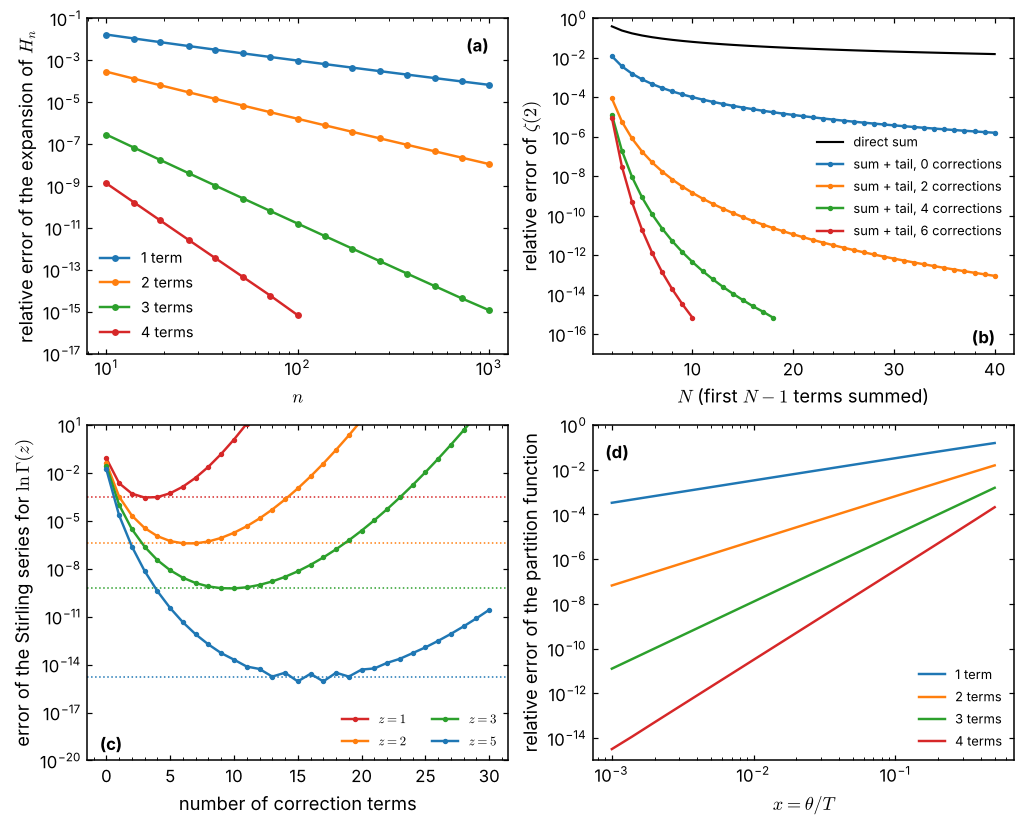

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
floor = lambda e, lo=4e-16: np.where(e > lo, e, np.nan)     # hide values at rounding level

ax = axes[0, 0]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(ns, floor(H_err[N] / H_exact), "o-", ms=3.5, color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel("$n$"); ax.set_ylabel(r"relative error of the expansion of $H_n$")
ax.set_ylim(1e-17, 1e-1); ax.legend(loc="lower left"); am.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
ax.semilogy(Ns, z_direct / zeta2, "k", lw=1.4, label="direct sum")
for K, c in zip((0, 2, 4, 6), ("C0", "C1", "C2", "C3")):
    ax.semilogy(Ns, floor(z_em[K] / zeta2), "o-", ms=2.5, color=c, label=f"sum + tail, {K} corrections")
ax.set_xlabel("$N$ (first $N - 1$ terms summed)"); ax.set_ylabel(r"relative error of $\zeta(2)$")
ax.set_ylim(1e-17, 1); ax.legend(loc="center right", fontsize=8.5); am.panel_label(ax, "(b)", x=0.9, y=0.08)

ax = axes[1, 0]
for z, c in zip((1.0, 2.0, 3.0, 5.0), ("C3", "C1", "C2", "C0")):
    k = np.arange(st_err[z].size)
    ax.semilogy(k, np.maximum(st_err[z], 1e-17), "o-", ms=2.5, color=c, label=f"$z = {z:g}$")
    ax.axhline(math.exp(-2 * math.pi * z) / (2 * math.pi * math.sqrt(z)), color=c, ls=":", lw=1)
ax.set_xlabel("number of correction terms"); ax.set_ylabel(r"error of the Stirling series for $\ln\Gamma(z)$")
ax.set_ylim(1e-20, 10); ax.legend(loc="lower right", ncol=2, fontsize=8.5); am.panel_label(ax, "(c)", y=0.08)

ax = axes[1, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(xs, q_err[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel(r"$x = \theta/T$"); ax.set_ylabel("relative error of the partition function")
ax.set_ylim(1e-15, 1); ax.legend(loc="lower right", fontsize=8.5); am.panel_label(ax, "(d)")
plt.show()

**(a)** Relative error of the expansion of the harmonic numbers with one to four terms
(values at the rounding level are not shown). **(b)** $\zeta(2)$ from the first $N - 1$ terms of the sum, alone and with the
Euler–Maclaurin tail with 0 to 6 Bernoulli corrections. **(c)** Error of the Stirling
series against the number of correction terms; dotted lines: $e^{-2\pi z}/(2\pi\sqrt z)$. **(d)** Relative error of Mulholland's
expansion of the rotational partition function.

## Summary

* The Euler–Maclaurin formula converts a sum into an integral plus corrections from
  the derivatives at the ends; it is an asymptotic series, usually divergent.
* Applied to a tail, it computes slowly convergent sums to full precision from a few
  terms.
* The Stirling series for $\ln\Gamma(z)$ is Euler–Maclaurin applied to $\ln n$; its
  optimal truncation error is of order $e^{-2\pi z}$.
* High-temperature expansions of partition functions, such as Mulholland's for the
  rigid rotor, are Euler–Maclaurin expansions; symbolic algebra does the derivatives.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* N. G. de Bruijn, *Asymptotic Methods in Analysis*, 3rd ed. (North-Holland, 1970;
  Dover, 1981).
* R. L. Graham, D. E. Knuth and O. Patashnik, *Concrete Mathematics*, 2nd ed.
  (Addison-Wesley, 1994).
* D. A. McQuarrie, *Statistical Mechanics* (Harper & Row, 1976; University
  Science Books, 2000).
* H. P. Mulholland, "An asymptotic expansion for
  $\sum_{n=0}^{\infty}(2n+1)\exp(-\sigma(n+\tfrac12)^2)$", *Proc. Cambridge
  Philos. Soc.* **24**, 280 (1928).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).

## Exercises

1. Derive the trapezoidal part of the Euler–Maclaurin formula by integrating
   $\int_n^{n+1}(x - n - \tfrac12)f'(x)\,\mathrm dx$ by parts, and obtain the $B_2$ term
   by integrating by parts once more.
2. Compute $\zeta(3)$ to twelve digits with ten terms of the sum and a few terms of the
   tail formula.
3. Show that the optimal number of terms in the Stirling series is about $\pi z$ and
   estimate the optimal error.
4. For a homonuclear molecule only even (or only odd) $J$ contribute. Show that the
   even-$J$ and odd-$J$ sums have the same Euler–Maclaurin expansion, half of
   Mulholland's, so that their difference lies beyond all orders in $x$. Using the
   Poisson summation formula, show that the difference is about
   $\pi^{3/2}x^{-3/2}e^{-\pi^2/4x}$, and check this numerically (Chapter 3).

---

**Previous:** [8. Steepest descent and saddle points](08_steepest_descent.ipynb) &nbsp;·&nbsp; **Next:** [10. Chemical physics: Kramers' escape rate](../part3_examples/10_kramers_escape_rate.ipynb)